<a href="https://colab.research.google.com/github/M-AKSHAYAA1410/logistics-data-analysis/blob/main/Week3_Hypothetical_Logistics_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

df = pd.read_csv("Week3_Hypothetical_Logistics_Dataset.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df.info())

Dataset shape: (90, 10)
  Shipment_ID        Date    Route Vehicle_Type  Shipment_Volume  Distance_km  \
0      SHP001  2026-07-01  Route E   Mini Truck               87         55.1   
1      SHP002  2026-07-02  Route A        Truck               20         25.0   
2      SHP003  2026-07-03  Route E        Truck               38        223.6   
3      SHP004  2026-07-04  Route B          Van               47        220.1   
4      SHP005  2026-07-05  Route D          Van               39        237.8   

   Delivery_Time_hours  Transportation_Cost_INR  Fuel_Consumed_L On_Time  
0                 4.52                  1504.03            14.04     Yes  
1                 2.48                   597.86             3.31     Yes  
2                 7.87                  3212.59            33.81      No  
3                 7.75                  3396.51            41.93      No  
4                 6.45                  3941.56            51.01     Yes  
<class 'pandas.core.frame.DataFrame'>
R

In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values:
Shipment_ID                0
Date                       0
Route                      0
Vehicle_Type               0
Shipment_Volume            0
Distance_km                0
Delivery_Time_hours        0
Transportation_Cost_INR    0
Fuel_Consumed_L            0
On_Time                    0
dtype: int64
Total missing values: 0
Duplicate rows: 0


In [ ]:
print(df.describe())

       Shipment_Volume  Distance_km  Delivery_Time_hours  \
count        90.000000    90.000000            90.000000   
mean         48.311111   187.611111             6.259556   
std          26.498948    83.343458             2.049571   
min           6.000000    25.000000             1.680000   
25%          28.500000   132.500000             4.855000   
50%          41.500000   180.400000             6.425000   
75%          71.500000   235.025000             7.645000   
max          99.000000   410.000000            11.300000   

       Transportation_Cost_INR  Fuel_Consumed_L  
count                90.000000        90.000000  
mean               3042.703778        36.111556  
std                1125.296822        15.497798  
min                 597.860000         3.310000  
25%                2274.600000        26.130000  
50%                3079.655000        36.265000  
75%                3695.300000        45.820000  
max                5756.500000        74.210000  


In [ ]:
correlation = df["Distance_km"].corr(
    df["Transportation_Cost_INR"]
)

print("Distance and cost correlation:", correlation)

Distance and cost correlation: 0.9819646965919517


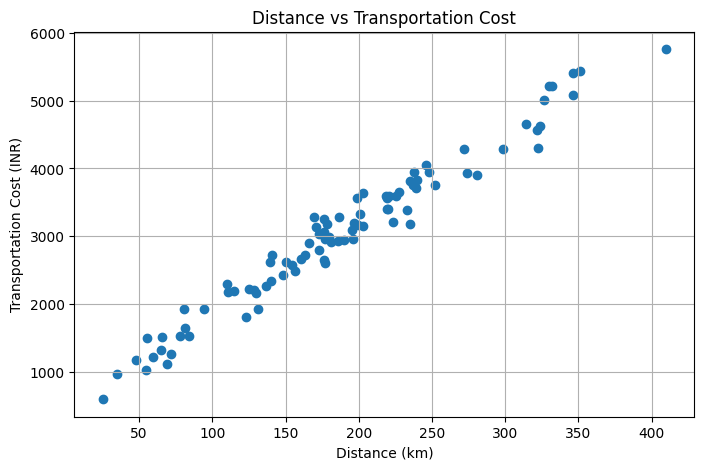

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Distance_km"],
    df["Transportation_Cost_INR"]
)

plt.xlabel("Distance (km)")
plt.ylabel("Transportation Cost (INR)")
plt.title("Distance vs Transportation Cost")

plt.grid(True)
plt.show()

In [ ]:
route_time = df.groupby("Route")["Delivery_Time_hours"].mean()

print(route_time)

Route
Route A    5.354000
Route B    6.302105
Route C    6.143846
Route D    6.260435
Route E    7.512000
Name: Delivery_Time_hours, dtype: float64


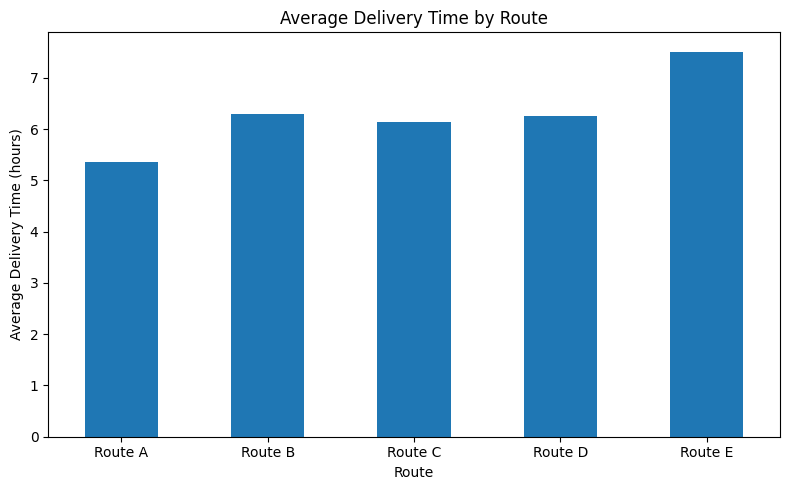

In [ ]:
import matplotlib.pyplot as plt

route_time = df.groupby("Route")["Delivery_Time_hours"].mean()

plt.figure(figsize=(8, 5))
route_time.plot(kind="bar")

plt.xlabel("Route")
plt.ylabel("Average Delivery Time (hours)")
plt.title("Average Delivery Time by Route")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Create an on-time indicator: Yes = 1, No = 0
df["On_Time_Flag"] = (df["On_Time"] == "Yes").astype(int)

# Calculate route-wise performance
route_performance = df.groupby("Route").agg(
    Total_Shipments=("Shipment_ID", "count"),
    Avg_Distance_km=("Distance_km", "mean"),
    Avg_Delivery_Time_hours=("Delivery_Time_hours", "mean"),
    Total_Cost=("Transportation_Cost_INR", "sum"),
    Total_Distance=("Distance_km", "sum"),
    Total_Fuel=("Fuel_Consumed_L", "sum"),
    On_Time_Rate=("On_Time_Flag", "mean")
)

# Calculate cost and fuel per kilometre
route_performance["Cost_per_km"] = (
    route_performance["Total_Cost"] /
    route_performance["Total_Distance"]
)

route_performance["Fuel_per_km"] = (
    route_performance["Total_Fuel"] /
    route_performance["Total_Distance"]
)

# Convert on-time rate into percentage
route_performance["On_Time_Rate"] *= 100

print(route_performance.round(2))

         Total_Shipments  Avg_Distance_km  Avg_Delivery_Time_hours  \
Route                                                                
Route A               20           168.27                     5.35   
Route B               19           196.17                     6.30   
Route C               13           158.22                     6.14   
Route D               23           199.88                     6.26   
Route E               15           209.23                     7.51   

         Total_Cost  Total_Distance  Total_Fuel  On_Time_Rate  Cost_per_km  \
Route                                                                        
Route A    54600.58          3365.4      626.13         55.00        16.22   
Route B    59506.91          3727.2      743.98         57.89        15.97   
Route C    34582.57          2056.8      399.23         53.85        16.81   
Route D    75102.18          4597.2      890.86         56.52        16.34   
Route E    50051.10          3138.4      

In [ ]:
on_time_count = (df["On_Time"] == "Yes").sum()
total_shipments = len(df)

on_time_percentage = (
    on_time_count / total_shipments
) * 100

print("On-time shipments:", on_time_count)
print("Total shipments:", total_shipments)
print("Overall on-time delivery rate:",
      round(on_time_percentage, 2), "%")

On-time shipments: 46
Total shipments: 90
Overall on-time delivery rate: 51.11 %


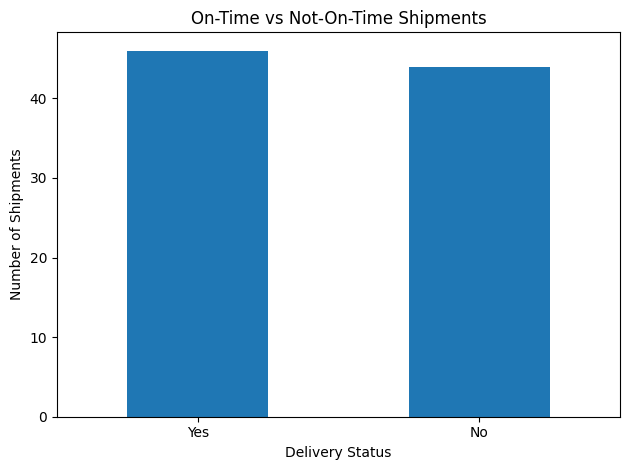

In [ ]:
import matplotlib.pyplot as plt

status_counts = df["On_Time"].value_counts()

status_counts.plot(kind="bar")

plt.xlabel("Delivery Status")
plt.ylabel("Number of Shipments")
plt.title("On-Time vs Not-On-Time Shipments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
avg_cost = df.groupby("Route")["Transportation_Cost_INR"].mean()

print("Average transportation cost per shipment:")
print(avg_cost.round(2))


Average transportation cost per shipment:
Route
Route A    2730.03
Route B    3131.94
Route C    2660.20
Route D    3265.31
Route E    3336.74
Name: Transportation_Cost_INR, dtype: float64


In [ ]:
correlation_time_distance = df["Distance_km"].corr(
    df["Delivery_Time_hours"]
)

print(
    "Distance and delivery time correlation:",
    round(correlation_time_distance, 3)
)

Distance and delivery time correlation: 0.895


In [ ]:
# Calculate implied average travel speed for each shipment
df["Average_Speed_kmh"] = (
    df["Distance_km"] / df["Delivery_Time_hours"]
)

# Compare average implied speed by route
route_speed = df.groupby("Route")["Average_Speed_kmh"].mean()

print("Average implied speed by route (km/h):")
print(route_speed.round(2))

Average implied speed by route (km/h):
Route
Route A    30.00
Route B    30.67
Route C    25.44
Route D    31.33
Route E    26.85
Name: Average_Speed_kmh, dtype: float64


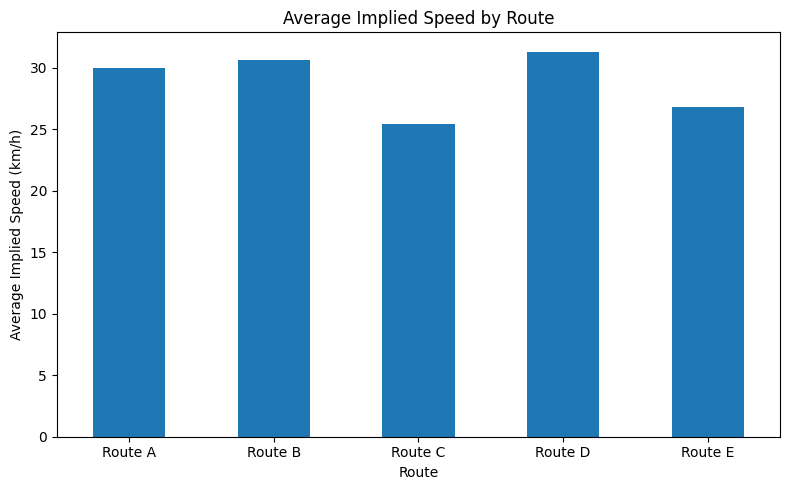

In [ ]:
import matplotlib.pyplot as plt

route_speed.plot(kind="bar", figsize=(8, 5))

plt.xlabel("Route")
plt.ylabel("Average Implied Speed (km/h)")
plt.title("Average Implied Speed by Route")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
vehicle_performance = df.groupby("Vehicle_Type").agg(
    Total_Shipments=("Shipment_ID", "count"),
    Avg_Distance_km=("Distance_km", "mean"),
    Avg_Delivery_Time_hours=("Delivery_Time_hours", "mean"),
    Avg_Cost=("Transportation_Cost_INR", "mean"),
    On_Time_Rate=("On_Time_Flag", "mean")
)

vehicle_performance["On_Time_Rate"] *= 100

print(vehicle_performance.round(2))

              Total_Shipments  Avg_Distance_km  Avg_Delivery_Time_hours  \
Vehicle_Type                                                              
Mini Truck                 22           193.86                     6.47   
Truck                      32           185.64                     6.20   
Van                        36           185.54                     6.18   

              Avg_Cost  On_Time_Rate  
Vehicle_Type                          
Mini Truck     3208.01         45.45  
Truck          2856.62         43.75  
Van            3107.09         61.11  


In [ ]:
route_e = df[df["Route"] == "Route E"]

route_e_performance = route_e.groupby("Vehicle_Type").agg(
    Total_Shipments=("Shipment_ID", "count"),
    Avg_Distance_km=("Distance_km", "mean"),
    Avg_Delivery_Time_hours=("Delivery_Time_hours", "mean"),
    On_Time_Rate=("On_Time_Flag", "mean")
)

route_e_performance["On_Time_Rate"] *= 100

print(route_e_performance.round(2))

              Total_Shipments  Avg_Distance_km  Avg_Delivery_Time_hours  \
Vehicle_Type                                                              
Mini Truck                  5           223.26                     7.86   
Truck                       7           185.90                     7.01   
Van                         3           240.27                     8.11   

              On_Time_Rate  
Vehicle_Type                
Mini Truck           20.00  
Truck                28.57  
Van                  33.33  


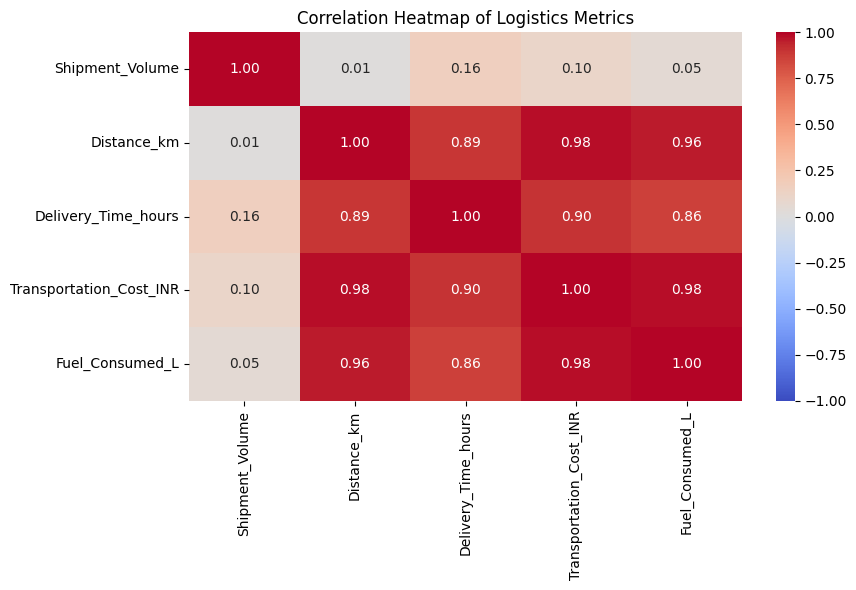

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_columns = [
    "Shipment_Volume",
    "Distance_km",
    "Delivery_Time_hours",
    "Transportation_Cost_INR",
    "Fuel_Consumed_L"
]

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Logistics Metrics")
plt.tight_layout()
plt.show()

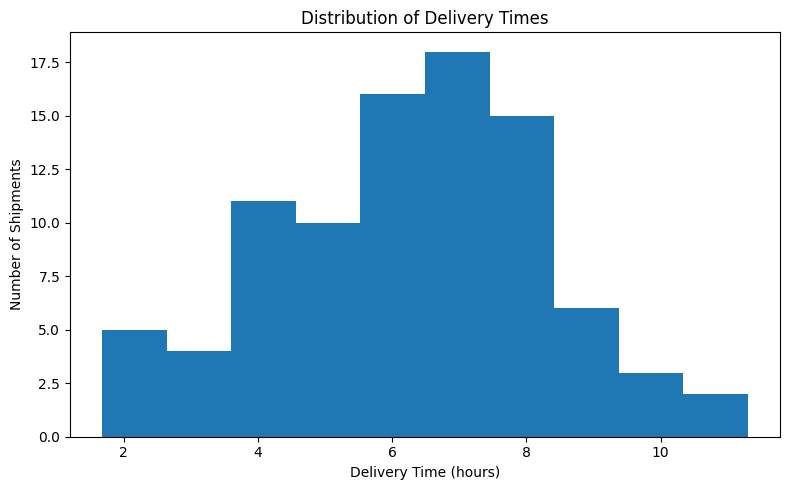

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["Delivery_Time_hours"], bins=10)

plt.xlabel("Delivery Time (hours)")
plt.ylabel("Number of Shipments")
plt.title("Distribution of Delivery Times")

plt.tight_layout()
plt.show()

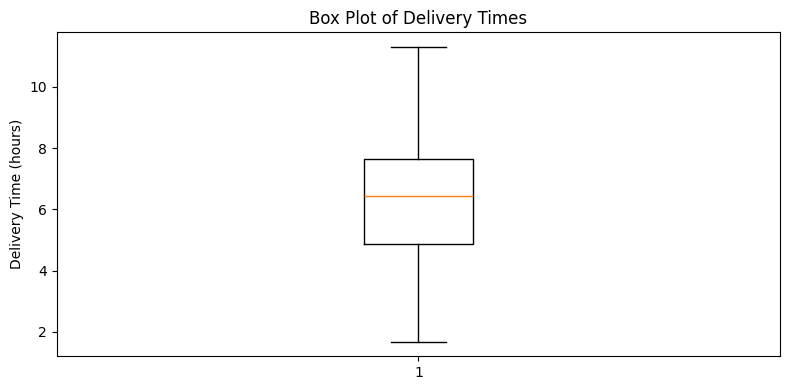

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.boxplot(df["Delivery_Time_hours"])

plt.ylabel("Delivery Time (hours)")
plt.title("Box Plot of Delivery Times")

plt.tight_layout()
plt.show()